In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 1. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [3]:
# 2. Normalize data
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [4]:
# Convert 28x28 images into 784 values
x_train = x_train.reshape((len(x_train), 784))
x_test = x_test.reshape((len(x_test), 784))

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


In [5]:
# 3. Define Encoder
encoding_dim = 32

input_img = keras.Input(shape=(784,))

encoded = layers.Dense(
    128, activation="relu"
)(input_img)

encoded = layers.Dense(
    encoding_dim, activation="relu"
)(encoded)

In [6]:
# 4. Define Decoder
decoded = layers.Dense(
    128, activation="relu"
)(encoded)

decoded = layers.Dense(
    784, activation="sigmoid"
)(decoded)

In [7]:
# 5. Create Autoencoder
autoencoder = keras.Model(input_img, decoded)

In [8]:
# 6. Compile model
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           4,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           4,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# 7. Train Autoencoder
autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.0093 - loss: 0.2261 - val_accuracy: 0.0092 - val_loss: 0.1494
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.0099 - loss: 0.1306 - val_accuracy: 0.0096 - val_loss: 0.1160
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.0098 - loss: 0.1126 - val_accuracy: 0.0092 - val_loss: 0.1073
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.0105 - loss: 0.1057 - val_accuracy: 0.0126 - val_loss: 0.1020
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.0113 - loss: 0.1016 - val_accuracy: 0.0121 - val_loss: 0.0990
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.0121 - loss: 0.0989 - val_accuracy: 0.0113 - val_loss: 0.0967
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.0122 - loss: 0.0970 - val_accuracy: 0.0122 - val_loss: 0.0952
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.0125 - loss: 0.0957 - val_accur

In [10]:
# 8. Anomaly Detection
decoded_imgs = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [11]:
# Calculate reconstruction error
error = np.mean(
    np.square(x_test - decoded_imgs),
    axis=1
)

In [12]:
# Set anomaly threshold
threshold = np.percentile(error, 95)

print("Anomaly Threshold:", threshold)

Anomaly Threshold: 0.020980572


In [13]:
# Detect anomalies
anomalies = error > threshold

print("Number of anomalies:", np.sum(anomalies))

Number of anomalies: 500


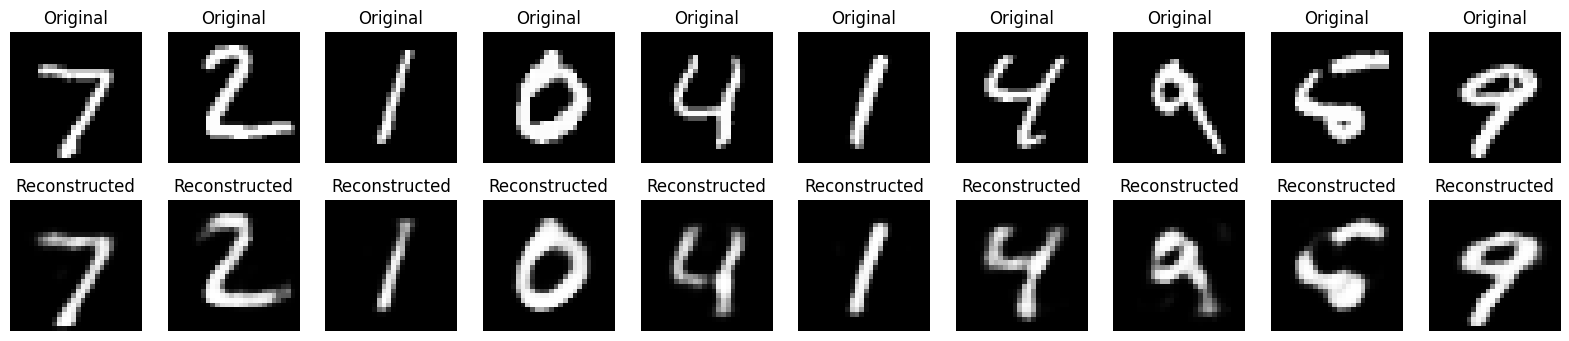

In [15]:
# 9. Display original and reconstructed images
n = 10

plt.figure(figsize=(20, 4))

for i in range(n):

    # Original image
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.show()

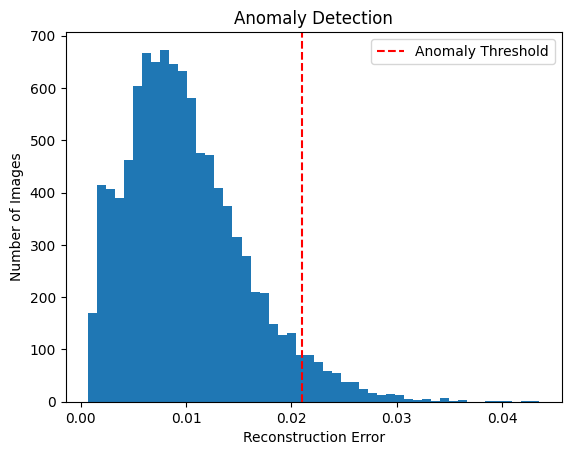

In [16]:
# 10. Plot reconstruction error
plt.hist(error, bins=50)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Anomaly Detection")
plt.legend()
plt.show()